# Lab 2: Spam Classification and Outlier Detection

**Course:** CSCN8000  
**Lab:** 2  
**Student Name:** Preethi Vasudevan Nair    
**Student Id:** 9125985     
**Date:** October 2026

## Introduction

The objective of this lab is to understand how probability and statistical techniques can be applied to real-world datasets.

The lab is divided into two parts:

- **Part A:** Classify emails as spam or not spam using Gaussian Naive Bayes and Multinomial Naive Bayes. Both models will be evaluated and compared to identify which performs better.
- **Part B:** Identify and remove outliers from the New York City Airbnb dataset using statistical techniques such as mean, median, standard deviation, interquartile range (IQR), and percentiles.

The results will be analyzed using statistical summaries, visualizations, and comparisons to understand the effectiveness of each approach.

## Part A: Email Spam Classification

### 1. Dataset Overview

This section uses an email dataset containing legitimate (ham) and spam messages.

The objective is to train and compare Gaussian Naive Bayes and Multinomial Naive Bayes models to identify spam emails.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

print("All libraries imported successfully.")

All libraries imported successfully.


In [2]:
# Load the email dataset
df = pd.read_csv("Lab2_dataset.csv")

# Display the first five records
print("Dataset shape:", df.shape)

display(df.head())

Dataset shape: (5171, 4)


,Unnamed: 0,label,text,label_num
0,605,ham,Subject: enron methanol ; meter # : 988291\nth...,0
1,2349,ham,"Subject: hpl nom for january 9 , 2001\n( see a...",0
2,3624,ham,"Subject: neon retreat\nho ho ho , we ' re arou...",0
3,4685,spam,"Subject: photoshop , windows , office . cheap ...",1
4,2030,ham,Subject: re : indian springs\nthis deal is to ...,0


In [3]:
# Display column information
df.info()

# Check for missing values
print("\nMissing values:")
print(df.isnull().sum())

# Check for duplicate rows
print("\nDuplicate rows:", df.duplicated().sum())

# Count spam and legitimate emails
print("\nEmail distribution:")
print(df["label"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 5171 entries, 0 to 5170
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Unnamed: 0  5171 non-null   int64
 1   label       5171 non-null   str  
 2   text        5171 non-null   str  
 3   label_num   5171 non-null   int64
dtypes: int64(2), str(2)
memory usage: 161.7 KB

Missing values:
Unnamed: 0    0
label         0
text          0
label_num     0
dtype: int64

Duplicate rows: 0

Email distribution:
label
ham     3672
spam    1499
Name: count, dtype: int64


#### Dataset - Observations

After loading the dataset, I found that it contains 5,171 emails and 4 columns. Out of these emails, 3,672 are legitimate (ham) and 1,499 are spam.

I also checked for missing values and duplicate rows, and there were none.

I noticed that the dataset has more legitimate emails than spam emails. Because of this, I will use stratified sampling when splitting the data so that both the training and testing sets have a similar proportion of spam and legitimate emails.

### 2. Data Preparation and Text Vectorization

In [4]:
# separating the email text X and labels Y
# X contains the email messages
X = df["text"]

# y contains the spam or ham labels
y = df["label_num"]

print("Total emails:", len(X))
print("Total labels:", len(y))

Total emails: 5171
Total labels: 5171


In [5]:
# Split the data into 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training emails:", len(X_train))
print("Testing emails:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training emails: 4136
Testing emails: 1035

Training class distribution:
label_num
0    2937
1    1199
Name: count, dtype: int64

Testing class distribution:
label_num
0    735
1    300
Name: count, dtype: int64


In [6]:
# Create the CountVectorizer
vectorizer = CountVectorizer()

# Learn vocabulary from training data and convert it to numbers
X_train_vectorized = vectorizer.fit_transform(X_train)

# Convert testing data using the same vocabulary
X_test_vectorized = vectorizer.transform(X_test)

print("Training data shape:", X_train_vectorized.shape)
print("Testing data shape:", X_test_vectorized.shape)

print("Total unique words:", len(vectorizer.vocabulary_))

Training data shape: (4136, 43788)
Testing data shape: (1035, 43788)
Total unique words: 43788


#### Data Preparation and Text Vectorization - Observation

I split the dataset into 80% training (4,136 emails) and 20% testing (1,035 emails), using stratified sampling to maintain the spam and ham proportions.

I used CountVectorizer to convert the email text into numerical values, which resulted in 43,788 unique words. I fitted the vectorizer only on the training data to avoid data leakage.

### 3. Naive Bayes Model Training

#### Step 3.1 — Train Multinomial Naive Bayes

In [7]:
# Train the Multinomial Naive Bayes model
multinomial_model = MultinomialNB()

multinomial_model.fit(X_train_vectorized, y_train)

# Predict labels for the testing data
y_pred_multinomial = multinomial_model.predict(X_test_vectorized)

print("Multinomial Naive Bayes trained successfully.")
print("Accuracy:", accuracy_score(y_test, y_pred_multinomial))

Multinomial Naive Bayes trained successfully.
Accuracy: 0.9768115942028985


#### Step 3.2 — Train Gaussian Naive Bayes

In [8]:
# Train Gaussian Naive Bayes in batches
gaussian_model = GaussianNB()

batch_size = 100

# Train using batches to reduce memory usage
for start in range(0, X_train_vectorized.shape[0], batch_size):
    end = start + batch_size

    X_batch = X_train_vectorized[start:end].toarray()
    y_batch = y_train.iloc[start:end]

    gaussian_model.partial_fit(
        X_batch,
        y_batch,
        classes=np.array([0, 1])
    )

print("Gaussian Naive Bayes trained successfully.")

Gaussian Naive Bayes trained successfully.


#### Step 3.3 — Predict using Gaussian Naive Bayes

In [9]:
# Predict test emails in smaller batches
gaussian_predictions = []

for start in range(0, X_test_vectorized.shape[0], batch_size):
    end = start + batch_size

    X_batch = X_test_vectorized[start:end].toarray()

    batch_predictions = gaussian_model.predict(X_batch)

    gaussian_predictions.extend(batch_predictions)

y_pred_gaussian = np.array(gaussian_predictions)

print("Gaussian Naive Bayes predictions completed.")
print("Accuracy:", accuracy_score(y_test, y_pred_gaussian))

Gaussian Naive Bayes predictions completed.
Accuracy: 0.9545893719806763


#### Step 3.4 — Compare both models

In [10]:
# Compare both Naive Bayes models
results = pd.DataFrame({
    "Model": ["GaussianNB", "MultinomialNB"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_gaussian),
        accuracy_score(y_test, y_pred_multinomial)
    ],
    "Precision": [
        precision_score(y_test, y_pred_gaussian),
        precision_score(y_test, y_pred_multinomial)
    ],
    "Recall": [
        recall_score(y_test, y_pred_gaussian),
        recall_score(y_test, y_pred_multinomial)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_gaussian),
        f1_score(y_test, y_pred_multinomial)
    ]
})

display(results.round(4))

,Model,Accuracy,Precision,Recall,F1-Score
0,GaussianNB,0.9546,0.9408,0.9000,0.9199
1,MultinomialNB,0.9768,0.9726,0.9467,0.9595


#### Model Training — Observation

I trained two classification models, Gaussian Naive Bayes and Multinomial Naive Bayes, using the email dataset.

MultinomialNB was trained using word counts directly, while GaussianNB was trained in smaller batches to reduce memory usage.

I used both models to predict the test emails and compared their performance using accuracy, precision, recall, and F1-score.

### 4. Model Evaluation and Comparison

#### Step 4.1 Confusion Matrix

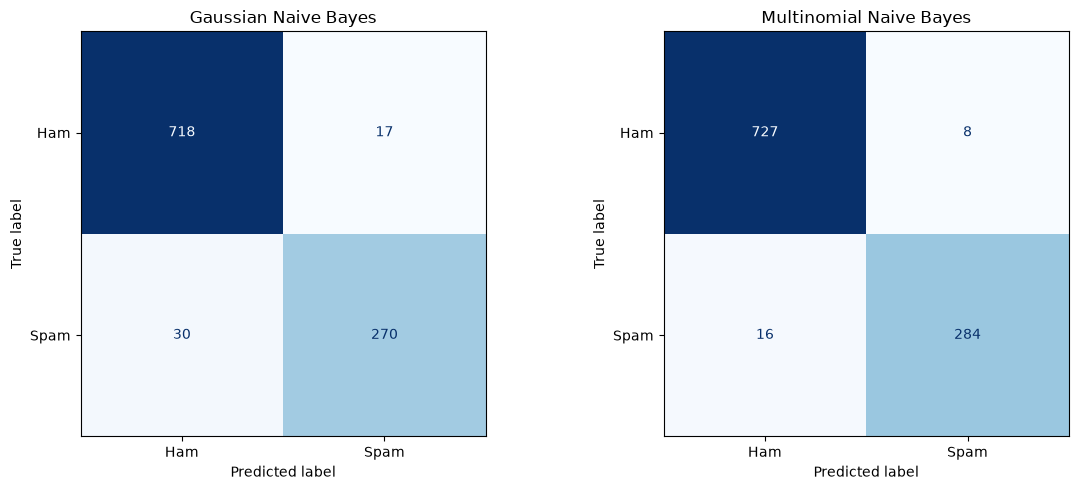

In [11]:
# Display confusion matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

models = [
    ("Gaussian Naive Bayes", y_pred_gaussian),
    ("Multinomial Naive Bayes", y_pred_multinomial)
]

for ax, (model_name, predictions) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Ham", "Spam"],
        cmap="Blues",
        ax=ax,
        colorbar=False
    )
    ax.set_title(model_name)

plt.tight_layout()
plt.show()

#### Step 4.2 — Select the Best Model

In [12]:
# Identify the model with the highest F1-score
best_result = results.loc[results["F1-Score"].idxmax()]

print("Best model based on F1-score:", best_result["Model"])
print("Accuracy:", round(best_result["Accuracy"], 4))
print("Precision:", round(best_result["Precision"], 4))
print("Recall:", round(best_result["Recall"], 4))
print("F1-score:", round(best_result["F1-Score"], 4))

Best model based on F1-score: MultinomialNB
Accuracy: 0.9768
Precision: 0.9726
Recall: 0.9467
F1-score: 0.9595


#### Step 4.3 — Predict Sample Emails

In [13]:
# Select the better-performing model
if best_result["Model"] == "MultinomialNB":
    best_predictions = y_pred_multinomial
else:
    best_predictions = y_pred_gaussian

# Compare actual and predicted labels for 10 test emails
sample_results = pd.DataFrame({
    "Email Preview": X_test.iloc[:10].str[:100].values,
    "Actual": y_test.iloc[:10].map({0: "Ham", 1: "Spam"}).values,
    "Predicted": pd.Series(best_predictions[:10]).map(
        {0: "Ham", 1: "Spam"}
    ).values
})

sample_results["Correct"] = (
    sample_results["Actual"] == sample_results["Predicted"]
)

display(sample_results)

,Email Preview,Actual,Predicted,Correct
0,Subject: final cp name change and merger repor...,Ham,Ham,True
1,Subject: calpine daily gas nomination\n- hidal...,Ham,Ham,True
2,Subject: calpine daily gas nomination\n>\naime...,Ham,Ham,True
3,"Subject: wells\ndaren , i think i may have los...",Ham,Ham,True
4,Subject: first deliveries - comstock oil & gas...,Ham,Ham,True
5,Subject: 3 . 25 rate confirmation # 367886924 ...,Spam,Spam,True
6,Subject: first delivery - rodessa operating co...,Ham,Ham,True
7,Subject: new pan energy exchange deal meeting\...,Ham,Ham,True
8,Subject: announcement for february 7\nplease t...,Ham,Ham,True
9,Subject: highest gains without guesswork\nwysa...,Spam,Spam,True


#### Model Evaluation — Observation


I evaluated both models using accuracy, precision, recall, F1-score, and confusion matrices to compare their performance.

I selected the model with the higher F1-score because it considers both precision and recall. I also tested the selected model on 10 emails from the test dataset and compared the predicted labels with the actual labels.

In [14]:
# Display the final comparison
display(results.round(4))

# Find the best model based on F1-score
best_model_name = best_result["Model"]

print("Best performing model:", best_model_name)

# Count correct predictions in the sample
correct_predictions = sample_results["Correct"].sum()

print("Correct sample predictions:", correct_predictions, "out of 10")

,Model,Accuracy,Precision,Recall,F1-Score
0,GaussianNB,0.9546,0.9408,0.9000,0.9199
1,MultinomialNB,0.9768,0.9726,0.9467,0.9595


Best performing model: MultinomialNB
Correct sample predictions: 10 out of 10


### 5. Part A Conclusion

In this part of the lab, I trained Gaussian Naive Bayes and Multinomial Naive Bayes models to classify emails as spam or legitimate.

After comparing both models, I found that **MultinomialNB performed better**, with an accuracy of **97.68%** and an F1-score of **95.95%**, compared to GaussianNB, which achieved **95.46% accuracy** and an **F1-score of 91.99%**.

MultinomialNB performed better in this experiment, which may be because it is better suited to word-count data, while GaussianNB assumes that the features follow a normal distribution, which may not be suitable for email word frequencies.

I also tested MultinomialNB on 10 emails from the test dataset, and it correctly classified all 10. However, this small sample does not guarantee that every future prediction will be correct.

Overall, this part helped me understand how Naive Bayes classifiers work and how accuracy, precision, recall, F1-score, and confusion matrices can be used to compare model performance.

## Part B: Airbnb Price Outlier Detection

### 1. Dataset Overview

In this part of the lab, I will use the New York City Airbnb dataset to identify and remove outliers based on the price per night.

I will explore the price distribution and compare different statistical methods, including mean, median, standard deviation, IQR, and percentiles, to find a suitable way to clean the dataset.

In [15]:
# Load the Airbnb dataset
airbnb_df = pd.read_csv("AB_NYC_2019.csv")

# Display dataset shape
print("Dataset Shape:", airbnb_df.shape)

# Display the first five rows
display(airbnb_df.head())

# Check column information
airbnb_df.info()

# Check missing values
print("\nMissing Values:")
print(airbnb_df.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", airbnb_df.duplicated().sum())

# Check price statistics
print("\nPrice Statistics:")
print(airbnb_df["price"].describe())

# Check zero and negative prices
print("\nZero Prices:", (airbnb_df["price"] == 0).sum())
print("Negative Prices:", (airbnb_df["price"] < 0).sum())

Dataset Shape: (48895, 16)


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

#### Dataset - Observations

After loading the Airbnb dataset, I found 48,895 listings with 16 columns. The dataset contains information such as location, room type, host details, and price per night.

Some columns have missing values, but the price column has no missing values. The average price is around $152.72, while the median is $106. The maximum price is $10,000, which is much higher than the average.

I also found 11 listings with a price of $0. These values, along with the unusually high prices, will be investigated during outlier detection.

### 2. Explore Price Distribution - Histogram and Boxplot

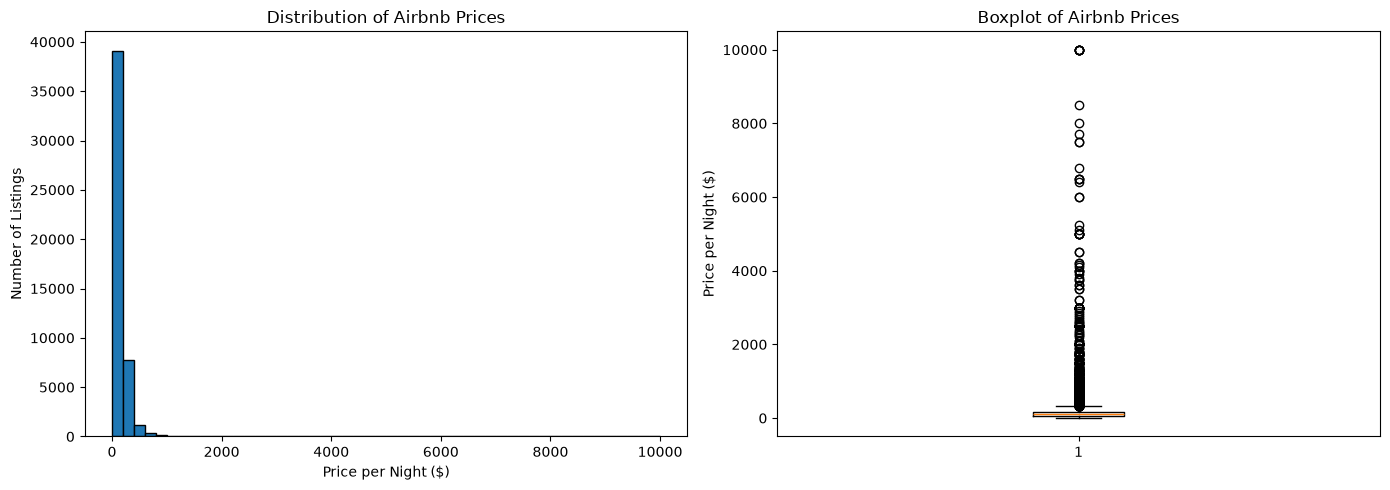

In [16]:
# Visualize Airbnb price distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of Airbnb prices
axes[0].hist(airbnb_df["price"], bins=50, edgecolor="black")
axes[0].set_title("Distribution of Airbnb Prices")
axes[0].set_xlabel("Price per Night ($)")
axes[0].set_ylabel("Number of Listings")

# Boxplot of Airbnb prices
axes[1].boxplot(airbnb_df["price"])
axes[1].set_title("Boxplot of Airbnb Prices")
axes[1].set_ylabel("Price per Night ($)")

plt.tight_layout()
plt.show()

#### Price Distribution — Observation

From the histogram, I noticed that most Airbnb listings are concentrated in the lower price range, while a few listings have very high prices. This shows that the data is right-skewed.

The boxplot also shows many potential outliers above the upper whisker, with some prices reaching $10,000 per night. These extreme values may affect the average price, so I will compare different statistical methods to identify and handle the outliers.

### 3. Calculate Statistical Measures

In [17]:
# Calculate statistical measures for Airbnb prices
prices = airbnb_df["price"]

mean_price = prices.mean()
median_price = prices.median()
std_price = prices.std()

# Calculate quartiles and IQR
Q1 = prices.quantile(0.25)
Q3 = prices.quantile(0.75)
IQR = Q3 - Q1

# Calculate percentiles
P1 = prices.quantile(0.01)
P5 = prices.quantile(0.05)
P95 = prices.quantile(0.95)
P99 = prices.quantile(0.99)

print("Mean Price:", round(mean_price, 2))
print("Median Price:", round(median_price, 2))
print("Standard Deviation:", round(std_price, 2))

print("\nQuartile and IQR Values:")
print("Q1 (25th Percentile):", Q1)
print("Q3 (75th Percentile):", Q3)
print("IQR:", IQR)

print("\nPercentile Values:")
print("1st Percentile:", P1)
print("5th Percentile:", P5)
print("95th Percentile:", P95)
print("99th Percentile:", P99)

Mean Price: 152.72
Median Price: 106.0
Standard Deviation: 240.15

Quartile and IQR Values:
Q1 (25th Percentile): 69.0
Q3 (75th Percentile): 175.0
IQR: 106.0

Percentile Values:
1st Percentile: 30.0
5th Percentile: 40.0
95th Percentile: 355.0
99th Percentile: 799.0


#### Statistical Measures — Observation

The average Airbnb price is $152.72, while the median is $106. The higher mean shows that expensive listings are pulling the average upward.

The standard deviation of $240.15 also shows a large variation in prices. The IQR is $106, and the 99th percentile is $799, meaning only about 1% of listings are priced above this value.

These results suggest that the dataset contains unusually high prices. I will use different statistical methods to identify and compare potential outliers before cleaning the data.

### 4. Outlier Detection Methods

In [18]:
# Method 1: IQR (Interquartile Range)
iqr_lower = Q1 - 1.5 * IQR
iqr_upper = Q3 + 1.5 * IQR

# Method 2: Mean and Standard Deviation (3-Sigma Rule)
std_lower = mean_price - 3 * std_price
std_upper = mean_price + 3 * std_price

# Method 3: Percentile Method (1st and 99th)
percentile_lower = P1
percentile_upper = P99

# Count outliers identified by each method
iqr_outliers = ((prices < iqr_lower) | (prices > iqr_upper)).sum()

std_outliers = ((prices < std_lower) | (prices > std_upper)).sum()

percentile_outliers = (
    (prices < percentile_lower) | (prices > percentile_upper)
).sum()

# Display comparison
outlier_comparison = pd.DataFrame({
    "Method": ["IQR", "Standard Deviation (3-Sigma)", "Percentile (1%-99%)"],
    "Lower Threshold": [iqr_lower, std_lower, percentile_lower],
    "Upper Threshold": [iqr_upper, std_upper, percentile_upper],
    "Outliers Detected": [
        iqr_outliers,
        std_outliers,
        percentile_outliers
    ]
})

display(outlier_comparison.round(2))

,Method,Lower Threshold,Upper Threshold,Outliers Detected
0,IQR,-90.00,334.00,2972
1,Standard Deviation (3-Sigma),-567.74,873.18,388
2,Percentile (1%-99%),30.00,799.00,878


#### Outlier Detection — Observation

I compared three methods to identify outliers in Airbnb prices. The IQR method uses an upper limit of $334, while the standard deviation method uses $873.18. The percentile method considers prices outside the $30 to $799 range.

I noticed that each method uses different limits, so the number of outliers detected can vary. The IQR method is more strict with high prices, while the standard deviation method allows a wider range.

Since the price distribution is right-skewed, I will compare the cleaned datasets before deciding which method is more suitable.

### 5. Compare Outlier Removal Methods

In [19]:
# Method 1: Remove outliers using IQR
airbnb_iqr = airbnb_df[
    (airbnb_df["price"] >= iqr_lower) &
    (airbnb_df["price"] <= iqr_upper)
].copy()

# Method 2: Remove outliers using Standard Deviation
airbnb_std = airbnb_df[
    (airbnb_df["price"] >= std_lower) &
    (airbnb_df["price"] <= std_upper)
].copy()

# Method 3: Remove outliers using Percentiles
airbnb_percentile = airbnb_df[
    (airbnb_df["price"] >= percentile_lower) &
    (airbnb_df["price"] <= percentile_upper)
].copy()

# Compare the original and cleaned datasets
cleaning_comparison = pd.DataFrame({
    "Dataset": [
        "Original",
        "IQR",
        "Standard Deviation",
        "Percentile"
    ],
    "Total Listings": [
        len(airbnb_df),
        len(airbnb_iqr),
        len(airbnb_std),
        len(airbnb_percentile)
    ],
    "Mean Price": [
        airbnb_df["price"].mean(),
        airbnb_iqr["price"].mean(),
        airbnb_std["price"].mean(),
        airbnb_percentile["price"].mean()
    ],
    "Median Price": [
        airbnb_df["price"].median(),
        airbnb_iqr["price"].median(),
        airbnb_std["price"].median(),
        airbnb_percentile["price"].median()
    ],
    "Maximum Price": [
        airbnb_df["price"].max(),
        airbnb_iqr["price"].max(),
        airbnb_std["price"].max(),
        airbnb_percentile["price"].max()
    ]
})

# Calculate removed listings
cleaning_comparison["Removed Listings"] = (
    len(airbnb_df) - cleaning_comparison["Total Listings"]
)

cleaning_comparison["Removed (%)"] = (
    cleaning_comparison["Removed Listings"] /
    len(airbnb_df) * 100
)

display(cleaning_comparison.round(2))

,Dataset,Total Listings,Mean Price,Median Price,Maximum Price,Removed Listings,Removed (%)
0,Original,48895,152.72,106.0,10000,0,0.00
1,IQR,45923,119.97,100.0,334,2972,6.08
2,Standard Deviation,48507,138.75,105.0,860,388,0.79
3,Percentile,48017,138.50,105.0,799,878,1.80


#### Data Cleaning — Observation

I applied three different methods to remove outliers and compared the results. The IQR method removed the most listings (2,972), reducing the average price from $152.72 to $119.97.

The standard deviation method removed 388 listings, while the percentile method removed 878. I noticed that each method affects the dataset differently, especially the average price.

I noticed that the IQR method removed more expensive listings, while the other methods kept more of them. I will consider these differences when selecting the final cleaned dataset.

### 6. Create the Final Cleaned Dataset

In [20]:
# Create the final cleaned dataset using the IQR method
# Remove zero-price listings and prices above the IQR upper limit

airbnb_cleaned = airbnb_df[
    (airbnb_df["price"] > 0) &
    (airbnb_df["price"] >= iqr_lower) &
    (airbnb_df["price"] <= iqr_upper)
].copy()

# Reset the index
airbnb_cleaned = airbnb_cleaned.reset_index(drop=True)

# Compare original and cleaned datasets
print("Original Listings:", len(airbnb_df))
print("Cleaned Listings:", len(airbnb_cleaned))
print("Removed Listings:", len(airbnb_df) - len(airbnb_cleaned))

print("\nCleaned Price Statistics:")
print(airbnb_cleaned["price"].describe())

# Check for remaining zero prices
print("\nZero Prices Remaining:",
      (airbnb_cleaned["price"] == 0).sum())

# Check that all prices are within the selected limits
print("Prices Above Original IQR Limit:",
      (airbnb_cleaned["price"] > iqr_upper).sum())

Original Listings: 48895
Cleaned Listings: 45912
Removed Listings: 2983

Cleaned Price Statistics:
count    45912.000000
mean       119.999063
std         68.133003
min         10.000000
25%         65.000000
50%        100.000000
75%        159.000000
max        334.000000
Name: price, dtype: float64

Zero Prices Remaining: 0
Prices Above Original IQR Limit: 0


#### Final Dataset Cleaning — Observation

I used the IQR method and removed listings with zero prices to create the final cleaned dataset.

After cleaning, 45,912 listings remained, and 2,983 listings were removed. The average price decreased from $152.72 to $120, and the maximum price decreased from $10,000 to $334.

The cleaned dataset has no zero prices or prices above the original IQR limit. This shows that the selected method reduced the effect of extreme prices on the dataset.

### 7. Before and After Cleaning

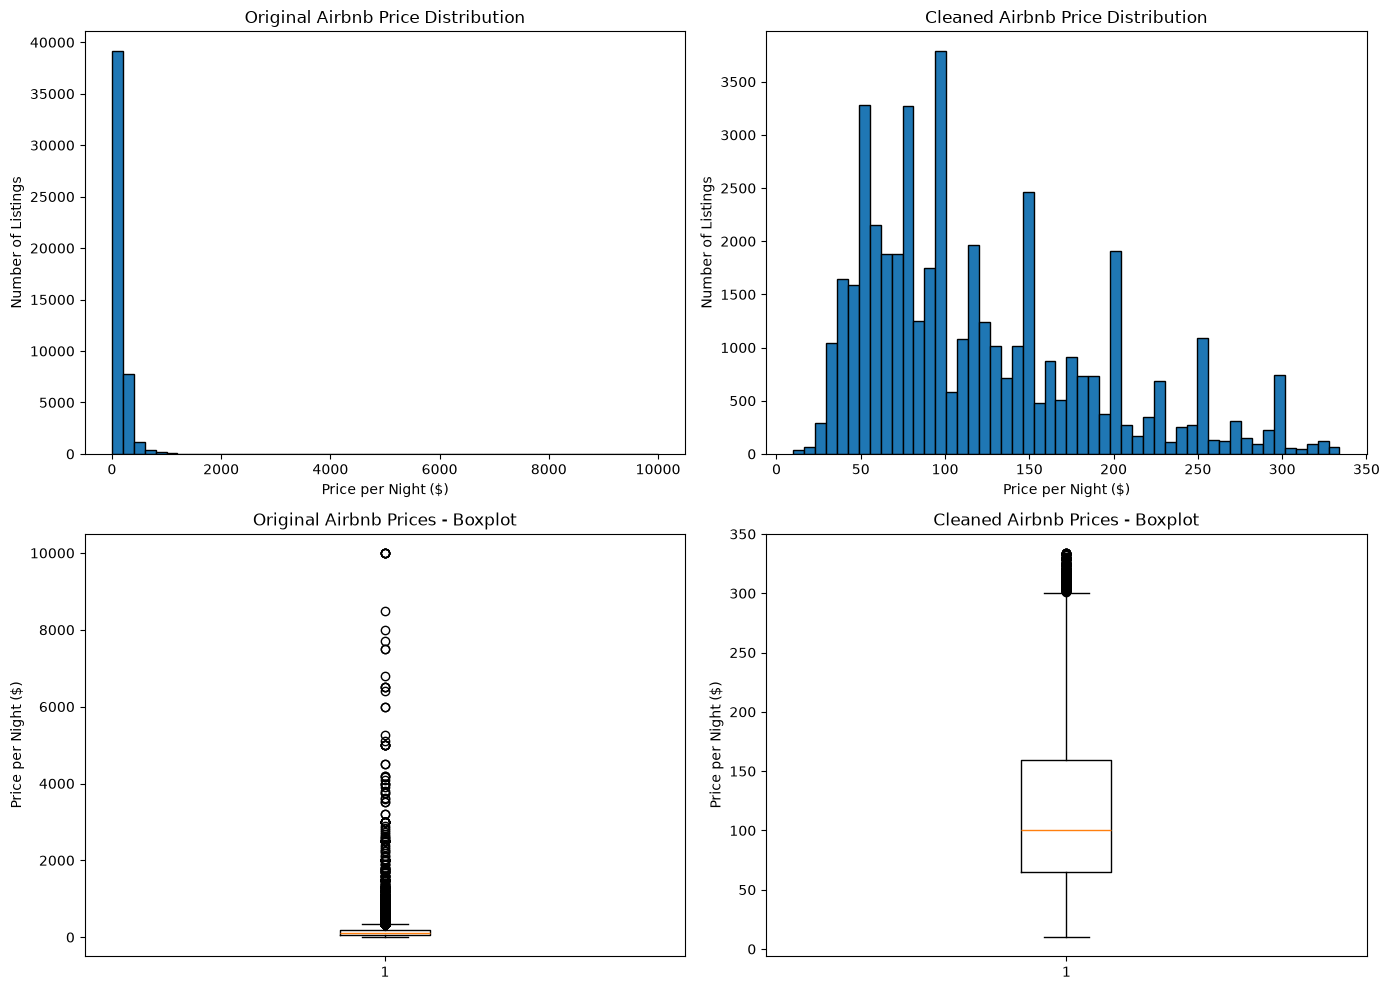

In [21]:
# Compare price distributions before and after cleaning
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Original dataset - Histogram
axes[0, 0].hist(airbnb_df["price"], bins=50, edgecolor="black")
axes[0, 0].set_title("Original Airbnb Price Distribution")
axes[0, 0].set_xlabel("Price per Night ($)")
axes[0, 0].set_ylabel("Number of Listings")

# Cleaned dataset - Histogram
axes[0, 1].hist(airbnb_cleaned["price"], bins=50, edgecolor="black")
axes[0, 1].set_title("Cleaned Airbnb Price Distribution")
axes[0, 1].set_xlabel("Price per Night ($)")
axes[0, 1].set_ylabel("Number of Listings")

# Original dataset - Boxplot
axes[1, 0].boxplot(airbnb_df["price"])
axes[1, 0].set_title("Original Airbnb Prices - Boxplot")
axes[1, 0].set_ylabel("Price per Night ($)")

# Cleaned dataset - Boxplot
axes[1, 1].boxplot(airbnb_cleaned["price"])
axes[1, 1].set_title("Cleaned Airbnb Prices - Boxplot")
axes[1, 1].set_ylabel("Price per Night ($)")

plt.tight_layout()
plt.show()

#### Before and After Cleaning — Observation

After comparing the graphs, I noticed that the original dataset had a large price range, with some listings reaching $10,000 per night.

After cleaning, the prices ranged from $10 to $334, making the distribution easier to understand. The extreme high prices were removed, and the boxplot showed a much smaller price range.

This comparison helped me understand how removing outliers changes the price distribution.

### 8. Export the Cleaned Dataset

In [22]:
# Save the final cleaned Airbnb dataset
airbnb_cleaned.to_csv("AB_NYC_2019_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

# Verify the exported dataset
saved_df = pd.read_csv("AB_NYC_2019_Cleaned.csv")

print("Saved dataset shape:", saved_df.shape)
print("Zero prices:", (saved_df["price"] == 0).sum())
print("Maximum price:", saved_df["price"].max())

Cleaned dataset saved successfully!
Saved dataset shape: (45912, 16)
Zero prices: 0
Maximum price: 334


### 9. Part B Conclusion

In this part of the lab, I analyzed the New York City Airbnb dataset containing 48,895 listings to identify and remove outliers based on price per night.

I first explored the price distribution using a histogram, boxplot, and statistical measures. I noticed that most listings had lower prices, while a few had extremely high prices reaching $10,000. The mean price was $152.72, which was higher than the median of $106, showing that expensive listings were affecting the average.

I compared three outlier detection methods: IQR, standard deviation, and percentiles. The IQR method identified 2,972 potential outliers, while the standard deviation and percentile methods identified 388 and 878 respectively. This showed me that different statistical methods can produce different results.

I selected the IQR method for the final cleaning because it is less affected by extreme values. I also removed 11 listings with zero prices. After cleaning, 45,912 listings remained, and a total of 2,983 listings were removed.

The average price decreased from $152.72 to approximately $120, and the standard deviation decreased from $240.15 to $68.13. The maximum price was reduced from $10,000 to $334.

The cleaned dataset was saved as a separate CSV file, keeping the original data unchanged. Although some expensive listings may be genuine luxury properties, this method helped reduce the influence of unusually high prices.

Overall, this part helped me understand how statistical measures can be used to identify outliers and how different cleaning methods can affect the final dataset.